# 03 · Como saber se está bom: avaliação de modelos

> **Capítulo 3 do livro:** *Evaluation Methodology*.
> Leia o capítulo antes ou depois: aqui as métricas viram código, medidas em texto de manutenção.

**Objetivo:** aprender as ferramentas para medir um modelo de linguagem: entropia e perplexidade, avaliação exata, similaridade com embeddings, IA como juiz e avaliação comparativa. E, mais importante, aprender **quando cada medida mente**.

## Antes de começar

- **Você precisa saber:** os notebooks 01 e 02 (modelo n-grama, tokens, amostragem, verificador).
- **Você não precisa de:** chave de API nem GPU. O "juiz" deste notebook é **simulado**, com defeitos conhecidos, para que dê para medir os defeitos. No capítulo 6 ele é trocado por um modelo de verdade, usando o mesmo protocolo.
- **Tempo:** 60 minutos.
- **Como estudar:** em cada "Pare e preveja", escreva o palpite antes de rodar.

## Mapa do notebook

1. Por que avaliar IA generativa é mais difícil
2. Entropia: quão incerto o modelo está
3. Entropia cruzada e perplexidade: quão surpreso ele fica com texto novo
4. Avaliação exata: o registro está certo?
5. Similaridade: palavras iguais, ou o mesmo significado?
6. IA como juiz: meça o juiz antes de confiar nele
7. Quando a métrica é a mesma que você otimizou
8. Avaliação comparativa: quem vence quem

In [1]:
import sys, pathlib, random
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import matplotlib.pyplot as plt

## 1. Por que avaliar IA generativa é mais difícil

Um classificador de falhas responde "falha" ou "planejada", e a resposta certa é uma só. Um modelo generativo escreve texto livre, e há **muitas respostas certas**.

Uma anotação de referência: `vedação do bico vazando`. Três candidatas:

In [2]:
from aiind.evaluation import exact_match, token_f1
ref = "vedação do bico vazando"
candidatas = {"igual": "vedação do bico vazando",
              "outras palavras, correta": "bico de enchimento com vazamento na vedação",
              "errada": "motor aquecendo"}
for nome, c in candidatas.items():
    print(f"{nome:26s} exato={exact_match(ref, c):.0f}   F1 de palavras={token_f1(ref, c):.2f}   {c}")

igual                      exato=1   F1 de palavras=1.00   vedação do bico vazando
outras palavras, correta   exato=0   F1 de palavras=0.36   bico de enchimento com vazamento na vedação
errada                     exato=0   F1 de palavras=0.00   motor aquecendo


### Pare e preveja

A candidata do meio diz a mesma coisa com outras palavras. Ela ganhou nota máxima ou mínima em comparação exata?

Ganhou **zero**, igual à errada. Comparar texto exato pune quem escreve diferente e acerta. Por outro lado, a nota por palavras em comum (F1) deu pouco à candidata correta, e uma candidata com muitas palavras repetidas e sentido oposto poderia ganhar mais. Avaliar texto livre exige escolher a medida certa para a pergunta que você quer responder, e este notebook percorre as principais.

## 2. Entropia: quão incerto o modelo está

No notebook 01 vimos que o modelo dá uma probabilidade a cada próximo token. A **entropia** resume essa distribuição num número: a incerteza média, em **bits**.

$$H(p) = -\sum_i p_i \log_2 p_i$$

Dois casos de referência: se uma só opção tem 100 %, a entropia é 0 bit (nenhuma surpresa); se 6 opções são igualmente prováveis, é log₂ 6 ≈ 2,58 bits. O número 2^H é o de **opções efetivas**: com quantas opções igualmente prováveis o modelo está "hesitando".

Vamos medir o trigrama do notebook 01 em contextos diferentes:

In [3]:
from aiind.corpus import notes
from aiind.tinylm import NGram, word_tokens, char_tokens
from aiind.evaluation import entropy
treino, teste = notes(2000), notes(400, seed=7)
tri = NGram(order=3).fit([word_tokens(t) for t in treino])
contextos = [[], ["enchedora"], ["enchedora", "parada"], ["bico", "de"], ["bico", "de", "enchimento"],
             ["tampadora", "parada", "garra"], ["voltou", "a"], ["vedação", "vazando"]]
print(f"{'contexto':32s} {'H (bits)':>9s} {'opções efetivas':>16s}   mais prováveis")
for c in contextos:
    p = tri.next_probs(c); h = entropy(p)
    top = ", ".join(f"{t} {v:.0%}" for t, v in sorted(p.items(), key=lambda kv: -kv[1])[:3])
    print(f"{' '.join(c) or '(início)':32s} {h:9.2f} {2**h:16.1f}   {top}")

contexto                          H (bits)  opções efetivas   mais prováveis
(início)                              2.59              6.0   prensa 18%, tampadora 17%, enchedora 17%
enchedora                             1.23              2.3   parada 77%, troca 11%, preventiva 5%
enchedora parada                      2.53              5.8   falta 20%, bico 19%, vedação 19%
bico de                               0.13              1.1   enchimento 99%, rolamento 0%, rotuladora 0%
bico de enchimento                    3.66             12.7   aquecendo 13%, vazando 11%, sem 11%
tampadora parada garra                2.82              7.1   quebrou 19%, desalinhado 17%, sem 17%
voltou a                              0.11              1.1   operar 99%, rolamento 0%, rotuladora 0%
vedação vazando                       2.30              4.9   chamado 39%, vedação 39%, aguardando 13%


Leia a tabela como uma conversa com o modelo:

- Depois de `bico de` quase não há dúvida: só `enchimento` cabe. Entropia perto de zero.
- Depois de `enchedora parada` o modelo hesita entre várias peças e motivos de parada. É incerteza **legítima**: a anotação pode continuar de muitos jeitos.
- O pico da tabela é depois de `bico de enchimento`: é o momento de nomear o sintoma, e há sintomas, chamados e fim da anotação disputando.
- O contexto `vedação vazando` abre um caminho a mais: a vedação pode ser repetida (peça trocada) ou vir um chamado.

Entropia alta não é defeito do modelo, é a incerteza real do texto. O defeito aparece quando o modelo está **muito seguro e errado**, e é isso que a próxima medida pega.

## 3. Entropia cruzada e perplexidade

A **entropia cruzada** mede quantos bits o modelo gasta, em média, para "codificar" um texto novo que veio da vida real:

$$H(p, q) = -\frac{1}{N}\sum_{t=1}^{N} \log_2 q(\text{token}_t \mid \text{contexto})$$

Se o modelo dá probabilidade alta ao que realmente apareceu, gasta poucos bits. Se dá probabilidade baixa, gasta muitos. A **perplexidade** é só 2 elevado a esse número, e se lê como as opções efetivas do modelo a cada passo:

$$\text{perplexidade} = 2^{H(p,q)}$$

### Pare e preveja

Treinamos modelos de ordem 1 a 5 (quantas palavras de contexto eles enxergam). Medimos a perplexidade no texto de **treino** e num texto **novo**. O que você espera? Mais contexto sempre melhora?

ordem 1: perplexidade no treino  40.74   em texto novo  39.96
ordem 2: perplexidade no treino   4.20   em texto novo   4.32
ordem 3: perplexidade no treino   3.15   em texto novo   3.63


ordem 4: perplexidade no treino   3.05   em texto novo   4.22


ordem 5: perplexidade no treino   2.72   em texto novo   4.30


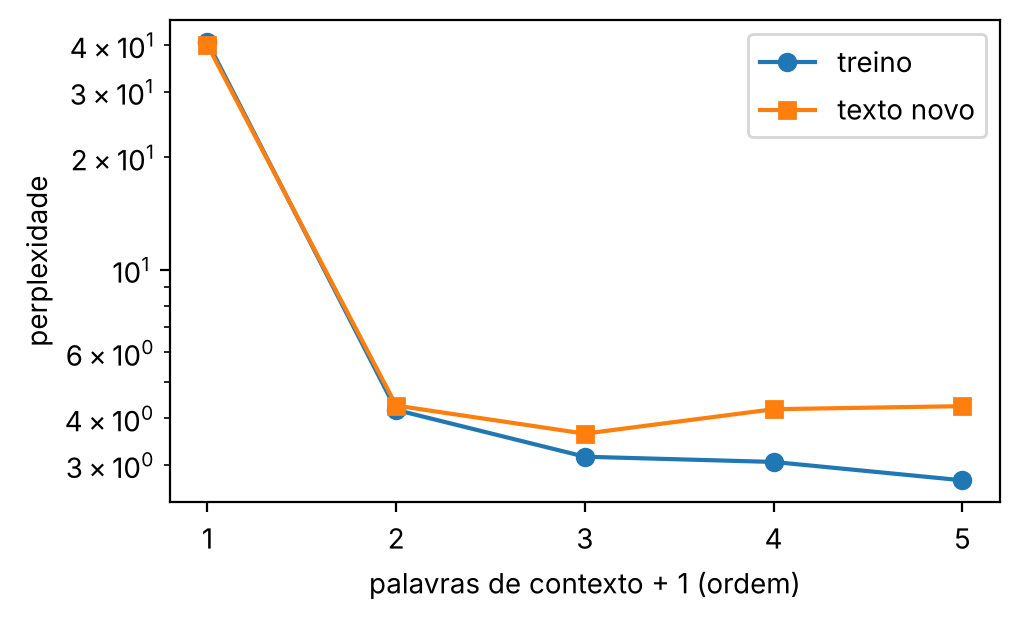

In [4]:
from aiind.evaluation import perplexity
tr_seqs, te_seqs = [word_tokens(t) for t in treino], [word_tokens(t) for t in teste]
ordens = [1, 2, 3, 4, 5]
ppl_tr, ppl_te = [], []
for o in ordens:
    m = NGram(order=o).fit(tr_seqs)
    ppl_tr.append(perplexity(m, tr_seqs[:400])); ppl_te.append(perplexity(m, te_seqs))
    print(f"ordem {o}: perplexidade no treino {ppl_tr[-1]:6.2f}   em texto novo {ppl_te[-1]:6.2f}")
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(ordens, ppl_tr, "o-", label="treino"); ax.plot(ordens, ppl_te, "s-", label="texto novo")
ax.set_yscale("log"); ax.set_xlabel("palavras de contexto + 1 (ordem)"); ax.set_ylabel("perplexidade"); ax.legend(); ax.set_xticks(ordens)
plt.tight_layout()

Três lições numa figura:

1. Passar de ordem 1 para 2 derruba a perplexidade de uns 40 para uns 4: o modelo parou de "chutar qualquer palavra".
2. Nos dados de **treino** a perplexidade continua caindo com a ordem. Em texto **novo**, ela para de cair na ordem 3 e **sobe** nas ordens 4 e 5. O modelo decorou o treino: **sobreajuste**.
3. Por isso perplexidade só vale em dados que o modelo **não viu**. Se um texto de teste tiver perplexidade suspeitamente baixa, ele pode ter vazado para o treino, e é uma das formas de detectar contaminação de benchmark.

### Perplexidade não é comparável entre tokenizadores

Cada token carrega uma quantidade diferente de texto. Um modelo de caracteres e um de palavras têm perplexidades por token incomparáveis. A medida que dá para comparar é **bits por caractere do texto original**:

In [5]:
from aiind.evaluation import bits_per_char
tri_p = NGram(order=3).fit(tr_seqs)
car5 = NGram(order=5).fit([char_tokens(t) for t in treino])
mc = lambda m, tok, textos: (perplexity(m, [tok(t) for t in textos]), bits_per_char(m, [tok(t) for t in textos], textos))
print(f"{'modelo':24s} {'perplexidade/token':>19s} {'bits por caractere':>19s}")
for nome, m, tok in [("palavras (ordem 3)", tri_p, word_tokens), ("caracteres (ordem 5)", car5, char_tokens)]:
    p, b = mc(m, tok, teste)
    print(f"{nome:24s} {p:19.2f} {b:19.3f}")

modelo                    perplexidade/token  bits por caractere
palavras (ordem 3)                      3.63               0.296


caracteres (ordem 5)                    1.33               0.422


A perplexidade por token do modelo de caracteres é **menor** (cada caractere é fácil de prever), mas o de palavras gasta menos bits por caractere do texto. Só a segunda comparação é justa. Nota: a conta do modelo de palavras inclui o fim da anotação, o de caracteres também.

### Perplexidade como alarme

Um modelo treinado nas anotações de uma fábrica fica **surpreso** com texto de outro tipo. Vamos testar o modelo de caracteres em três textos: anotações novas, as mesmas anotações traduzidas para inglês, e as mesmas palavras embaralhadas.

anotações novas             0.42 bits por caractere   ex.: rotuladora parada sensor de etiqueta travou chamado manutenção sensor de etiqueta ajustado
traduzidas para inglês      5.99 bits por caractere   ex.: labeler stopped sensor label jammed called maintenance sensor label adjusted
palavras embaralhadas       2.87 bits por caractere   ex.: parada de sensor travou etiqueta sensor de manutenção etiqueta rotuladora ajustado chamado


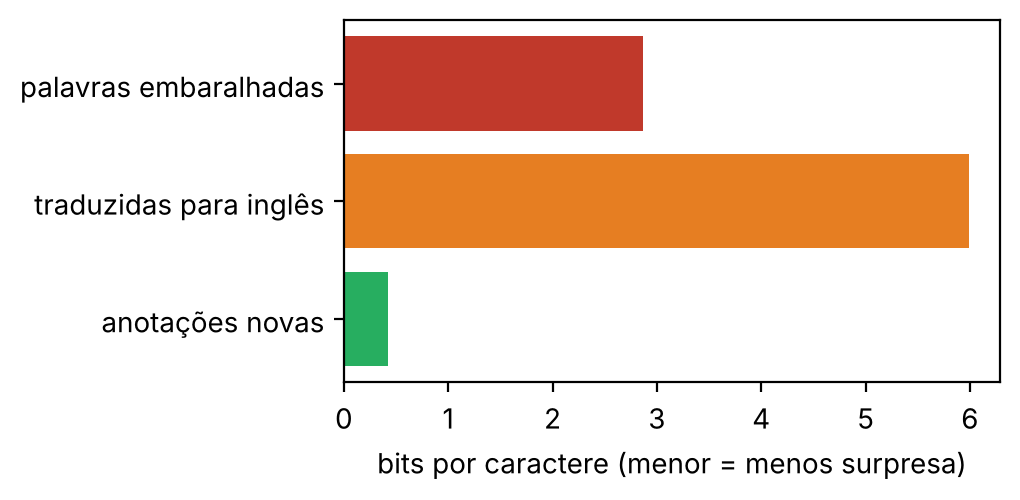

In [6]:
from aiind.foundation import to_english
rr = random.Random(0)
embaralhadas = []
for t in teste:
    w = t.split(); rr.shuffle(w); embaralhadas.append(" ".join(w))
tipos = {"anotações novas": teste, "traduzidas para inglês": [to_english(t) for t in teste], "palavras embaralhadas": embaralhadas}
bpc = {k: bits_per_char(car5, [char_tokens(t) for t in v], v) for k, v in tipos.items()}
for k, v in bpc.items():
    print(f"{k:26s} {v:5.2f} bits por caractere   ex.: {tipos[k][0]}")
fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.barh(list(bpc), list(bpc.values()), color=["#27ae60", "#e67e22", "#c0392b"]); ax.set_xlabel("bits por caractere (menor = menos surpresa)")
plt.tight_layout()

O modelo gasta bem mais bits no inglês e nas palavras embaralhadas. Na prática isso vira **monitoramento**: calcule a perplexidade das anotações que chegam em produção, e uma subida repentina avisa que mudou o tipo de texto (um novo operador, outro idioma, outra linha), antes de qualquer reclamação.

Perplexidade, porém, **mede o modelo de linguagem, não a utilidade**. Um modelo pode ter perplexidade ótima e extrair o registro errado. Para saber se o sistema cumpre a tarefa, é preciso medir a tarefa.

## 4. Avaliação exata: o registro está certo?

Quando existe uma resposta objetivamente certa, a avaliação pode ser **exata**: comparar com o gabarito ou executar o resultado e ver se funciona (**correção funcional**). No notebook 02 transformamos anotações em JSON. Agora vamos medir de formas diferentes, com os três sistemas que já temos: o extrator por regras, o trigrama gerando livre e o trigrama com decodificação restrita.

In [7]:
from aiind.structured import labeled, training_sequences, schema_allowed, parse, valid, FIELDS, SEP, rule_extract
from aiind.sampling import generate
dados_tr, dados_te = labeled(3000), labeled(200, seed=7)
extrator = NGram(order=3).fit(training_sequences(dados_tr))

def por_regras(nota):
    return rule_extract(nota)

def gerador(restrito):
    rng = random.Random(0)
    def f(nota):
        prompt = nota.split() + [SEP]
        toks, _ = generate(extrator, rng, prompt=prompt, max_len=len(prompt) + 16,
                           allowed=schema_allowed(len(prompt)) if restrito else None)
        return parse(toks[len(prompt):])
    return f

def medir(predizer, dados):
    r = dict(valido=0, exato=0, campos=0, categoria=0)
    for nota, certo in dados:
        rec = predizer(nota)
        if rec is None:
            continue
        r["valido"] += not valid(rec)
        r["exato"] += rec == certo
        r["campos"] += sum(rec.get(f) == certo[f] for f in FIELDS)
        r["categoria"] += rec.get("categoria") == certo["categoria"]
    n = len(dados)
    return {"JSON válido": r["valido"] / n, "registro exato": r["exato"] / n,
            "campos certos": r["campos"] / (4 * n), "categoria certa": r["categoria"] / n}

sistemas = {"regras": por_regras, "trigrama livre": gerador(False), "trigrama restrito": gerador(True)}
resultados = {nome: medir(f, dados_te) for nome, f in sistemas.items()}
print(f"{'sistema':20s}" + "".join(f"{k:>18s}" for k in next(iter(resultados.values()))))
for nome, r in resultados.items():
    print(f"{nome:20s}" + "".join(f"{v:18.0%}" for v in r.values()))

sistema                    JSON válido    registro exato     campos certos   categoria certa
regras                            100%              100%              100%              100%
trigrama livre                     30%                0%               18%               34%
trigrama restrito                 100%                0%               27%               38%


Cada coluna responde uma pergunta diferente:

- **JSON válido:** o sistema entrega algo que o programa seguinte consegue ler?
- **Registro exato:** o registro inteiro está igual ao gabarito? É a medida mais dura.
- **Campos certos:** quantos dos 4 campos acertou, em média? Mostra quase-acertos que o exato esconde.
- **Categoria certa:** é a medida **funcional** para o OEE. O cálculo de disponibilidade só precisa saber se a parada foi falha, planejada, falta de material ou retorno. Aqui os dois trigramas vão mal até nessa coluna, mas com um modelo melhor é comum o registro exato ficar baixo (a peça escrita de outro jeito) e a categoria continuar alta, e o sistema servir ao OEE do mesmo jeito.

A escolha da métrica é uma decisão de engenharia: **mede-se o que o processo seguinte consome**. Para um gráfico de Pareto de peças, o campo `peca` importa. Para a perda por categoria do OEE, só a `categoria`.

Medir por **fatias** também ajuda. Veja onde o extrator por regras erra, por categoria verdadeira:

In [8]:
from collections import defaultdict
por_cat = defaultdict(list)
for nota, certo in dados_te:
    por_cat[certo["categoria"]].append(por_regras(nota) == certo)
for cat, v in por_cat.items():
    print(f"{cat:10s} {sum(v)/len(v):6.1%}   ({len(v)} casos)")

falha      100.0%   (116 casos)
falta       96.7%   (30 casos)
planejada  100.0%   (42 casos)
retorno    100.0%   (12 casos)


O único erro está na fatia `falta`, o caso da "garrafa" que vimos no notebook 02. Uma média alta pode esconder uma fatia ruim, e fatias pequenas dão números instáveis, então anote quantos casos há em cada. Em produção, fatie por máquina, turno e tipo de parada.

## 5. Similaridade: palavras iguais, ou o mesmo significado?

Quando a resposta é texto livre, não dá para exigir igualdade. Há três famílias de medida:

| Família | Exemplo | Vê | Não vê |
|---|---|---|---|
| exata | igualdade | só o idêntico | qualquer paráfrase |
| **lexical** | palavras em comum, distância de edição | texto parecido | sinônimos |
| **semântica** | similaridade entre embeddings | o mesmo sentido com outras palavras | detalhes como negação |

Um **embedding** transforma um texto num vetor, de modo que textos de sentido parecido ficam perto. Modelos de embedding reais são redes treinadas. Aqui vamos construir o ingrediente mais simples da ideia: palavras que aparecem nas mesmas anotações ganham vetores parecidos. Receita: contar quais palavras aparecem juntas, converter em PMI (quanto mais que o acaso), e comprimir com uma decomposição SVD.

O corpus é de anotações de falha escritas de formas diferentes: "vazando", "vazamento", "pingando", "escorrendo" aparecem com as mesmas peças.

In [9]:
from aiind.evaluation import Embedder, fault_notes, paraphrase_pairs, FAMILIES, auc, token_f1, char_similarity
emb = Embedder(dim=12).fit([t for t, _, _ in fault_notes(3000)])
for w in ["vazando", "travou", "aquecendo"]:
    print(f"mais perto de {w!r}: " + ", ".join(f"{p} ({s:.2f})" for p, s in emb.nearest(w, 4)))

mais perto de 'vazando': pingando (1.00), escorrendo (1.00), vazamento (0.99), enchedora (0.55)
mais perto de 'travou': bloqueado (1.00), emperrou (1.00), preso (1.00), na (0.55)
mais perto de 'aquecendo': superaquecendo (1.00), esquentando (1.00), quente (1.00), vazando (0.31)


O modelo nunca recebeu um dicionário de sinônimos, e mesmo assim `vazando`, `pingando`, `escorrendo` e `vazamento` ficaram juntos, porque aparecem ao lado das mesmas peças. É a ideia por trás de todo embedding: **o significado de uma palavra vem das companhias que ela tem**. Em duas dimensões:

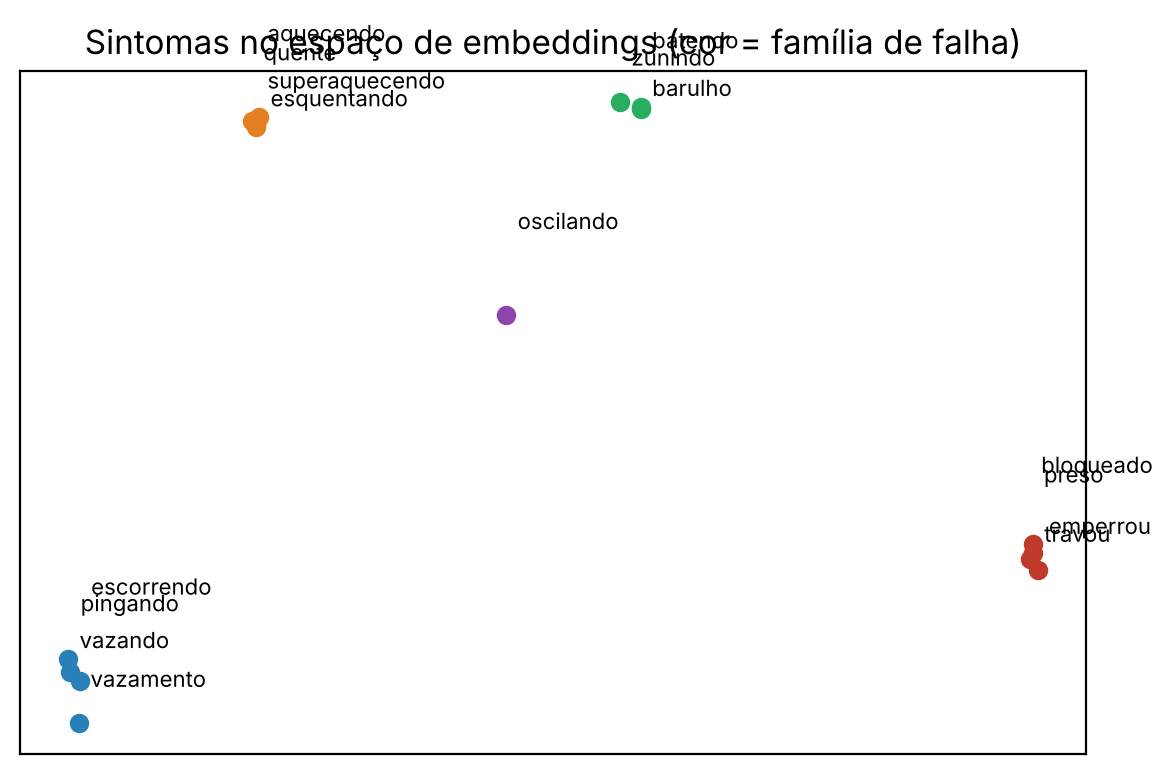

In [10]:
import numpy as np
simb = [(s, fam) for fam, d in FAMILIES.items() for s in d["sintomas"]]
palavras = [(w, f) for w, f in simb if w in emb.idx]
M = np.array([emb.W[emb.idx[w]] for w, _ in palavras]); M = M - M.mean(0)
U, S, _ = np.linalg.svd(M, full_matrices=False); P = U[:, :2] * S[:2]
cores = dict(zip(FAMILIES, ["#2980b9", "#c0392b", "#27ae60", "#e67e22", "#8e44ad"]))
fig, ax = plt.subplots(figsize=(6, 4))
for i, ((w, f), (x, y)) in enumerate(zip(palavras, P)):
    ax.scatter(x, y, color=cores[f]); ax.annotate(w, (x, y), fontsize=8, xytext=(4, 4 + 9 * (i % 4)), textcoords="offset points")
ax.set_title("Sintomas no espaço de embeddings (cor = família de falha)"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

Cada família de falha forma um grupo. Agora o teste que interessa: dadas duas anotações, dizer se descrevem a **mesma falha**. Montamos 600 pares: metade com a mesma falha escrita com sintomas diferentes, metade com falhas diferentes. A medida de qualidade é a **AUC**: a chance de uma amostra aleatória do grupo "mesma falha" receber nota maior que uma do grupo "falhas diferentes" (0,5 é acaso, 1 é perfeito).

In [11]:
pares = paraphrase_pairs(600)
pos = [(a, b) for a, b, y in pares if y]; neg = [(a, b) for a, b, y in pares if not y]
medidas = {"palavras em comum (F1)": token_f1, "caracteres parecidos": char_similarity, "embeddings": emb.similarity}
for nome, f in medidas.items():
    print(f"{nome:26s} AUC = {auc([f(a, b) for a, b in pos], [f(a, b) for a, b in neg]):.2f}")
a, b, y = pares[0]; print("\nexemplo de par, mesma falha:", y, "\n  ", a, "\n  ", b, f"\n   similaridade por embeddings: {emb.similarity(a, b):.2f}")

palavras em comum (F1)     AUC = 0.69


caracteres parecidos       AUC = 0.64


embeddings                 AUC = 0.94

exemplo de par, mesma falha: True 
   parada na tampadora cabeçote emperrou 
   paletizadora parada garra preso 
   similaridade por embeddings: 0.94


A semântica separa bem melhor que as medidas lexicais, porque reconhece sinônimos. Mas há um ponto cego clássico:

In [12]:
base = "vedação vazando"
for outra in ["vedação pingando", "vedação sem vazamento", "motor aquecendo"]:
    print(f"{base!r} x {outra!r:28s} similaridade {emb.similarity(base, outra):.2f}")

'vedação vazando' x 'vedação pingando'           similaridade 1.00
'vedação vazando' x 'vedação sem vazamento'      similaridade 0.89
'vedação vazando' x 'motor aquecendo'            similaridade 0.11


`vedação sem vazamento` quase empata com o sinônimo verdadeiro, embora diga o **contrário**. Embeddings medem "do que se trata", não "o que se afirma". Negação, números ("50 mm" contra "5 mm") e ordem de eventos escapam. Para a fábrica isso significa: similaridade serve para achar anotações **sobre o mesmo assunto** (busca de falhas parecidas), mas não para **validar** que duas anotações dizem a mesma coisa.

## 6. IA como juiz: meça o juiz antes de confiar nele

Quando não há gabarito e a resposta é longa, um modelo pode dar nota a outro: **IA como juiz**. É barato, escala e aceita critérios em linguagem natural. Mas o juiz **é um modelo**, com defeitos próprios. Dois bem documentados: **viés de posição** (prefere a primeira opção) e **viés de verbosidade** (prefere respostas longas).

Um juiz precisa de um critério escrito, uma **rubrica**. Exemplo para resumos de parada:

```text
Você avalia resumos de anotações de parada de máquina.
Nota de 1 a 5. Dê nota alta apenas se o resumo:
  (a) cita a máquina e a peça que aparecem na anotação;
  (b) cita o sintoma da anotação;
  (c) não inventa nenhuma informação que não esteja na anotação.
Tamanho não conta ponto. Responda só o número.
```

Para praticar o **protocolo de medir um juiz**, usamos um juiz simulado (`SimJudge`) com ruído, viés de verbosidade e viés de posição conhecidos. Com um modelo real o protocolo é o mesmo: troca-se a função que dá a nota. Os resumos têm qualidade conhecida: curtos ou longos, certos ou errados.

In [13]:
from aiind.evaluation import summaries, SimJudge, debiased_prefer, cohen_kappa
S = summaries(1000)
juiz = SimJudge(noise=0.8, length_bias=1.6, position_bias=0.5, seed=1)
exemplos = {k: next(s for s in S if s.kind == k) for k in ["curta certa", "longa errada", "vaga"]}
for k, s in exemplos.items():
    print(f"[{k}]  anotação: {s.note}\n    resumo:  {s.text}\n")
notas = defaultdict(list)
for s in S:
    notas[s.kind].append(juiz.score(s))
print("nota média do juiz por tipo de resumo:")
for k, v in notas.items():
    print(f"   {k:14s} {sum(v)/len(v):.2f}")

[curta certa]  anotação: prensa parada mangueira desalinhado
    resumo:  Falha: mangueira desalinhado (prensa).

[longa errada]  anotação: rotuladora parada sensor de etiqueta travou
    resumo:  A rotuladora parou por falha: o componente faca apresentou o sintoma 'travou'. Recomenda-se inspecionar o faca e acionar a manutenção para correção.

[vaga]  anotação: paletizadora parada garra sem leitura
    resumo:  A paletizadora apresentou um problema.

nota média do juiz por tipo de resumo:
   curta certa    3.44
   longa certa    4.35
   curta errada   1.48
   longa errada   2.48
   vaga           1.48


### Pare e preveja

O resumo **longo e errado** (cita a peça errada com muitas palavras) deveria receber nota mais baixa que o **curto e certo**. Receberá?

Veja a média: o longo errado ficou **acima** do curto errado e do vago, embora todos errem. O tamanho está comprando nota. Quanto? Três medidas, que formam o protocolo.

**Medida 1: concordância com pessoas.** Para saber se o juiz acerta, precisa de um conjunto pequeno rotulado por humanos. Escolha o corte de aprovação nesse conjunto e meça o resto. Usamos o kappa de Cohen, que desconta a concordância por acaso (1 = perfeito, 0 = acaso).

In [14]:
verdade = [int(s.correct) for s in S]
nota_j = [juiz.score(s) for s in S]
calib, resto = range(0, 100), range(100, len(S))
melhor = max((c / 4 for c in range(4, 20)), key=lambda c: cohen_kappa([verdade[i] for i in calib], [int(nota_j[i] >= c) for i in calib]))
pred = [int(nota_j[i] >= melhor) for i in resto]
alvo = [verdade[i] for i in resto]
print(f"corte escolhido com 100 exemplos rotulados: {melhor}")
print(f"nos outros {len(alvo)}: acerto {sum(a == b for a, b in zip(pred, alvo))/len(alvo):.0%}, kappa {cohen_kappa(alvo, pred):.2f}")

corte escolhido com 100 exemplos rotulados: 3.0
nos outros 900: acerto 85%, kappa 0.68


Concordância razoável no conjunto inteiro, mas é uma média, e o problema do juiz está em **casos específicos**. Medidas 2 e 3 olham para eles.

**Medida 2: viés de posição.** Pegue pares em que sabemos quem é melhor (curto certo contra longo errado) e pergunte em **ordem trocada**. Um juiz sem viés acerta igual nas duas ordens.

**Medida 3: viés de verbosidade.** O mesmo par já testa isto: o errado é o longo.

In [15]:
K = lambda k: [s for s in S if s.kind == k]
certo, errado = K("curta certa"), K("longa errada")
j = SimJudge(noise=0.8, length_bias=1.6, position_bias=0.5, seed=5)
n = len(certo)
certo_primeiro = sum(j.prefer(a, b) == "A" for a, b in zip(certo, errado)) / n
certo_segundo = sum(j.prefer(b, a) == "B" for a, b in zip(certo, errado)) / n
print(f"juiz escolhe o resumo certo quando ele vem primeiro: {certo_primeiro:.0%}")
print(f"juiz escolhe o resumo certo quando ele vem depois:   {certo_segundo:.0%}   (50 % seria moeda ao ar)")

juiz escolhe o resumo certo quando ele vem primeiro: 88%
juiz escolhe o resumo certo quando ele vem depois:   56%   (50 % seria moeda ao ar)


Quando o resumo certo vem em segundo lugar, o juiz se aproxima do acaso: o viés de posição e o de verbosidade somam contra ele.

**O que fazer:**

- **Trocar a ordem e exigir concordância.** Pergunte nas duas ordens. Se as respostas divergirem, o veredito é "empate".
- **Comparar só respostas de tamanho parecido**, ou dizer na rubrica que tamanho não conta (e **medir** se funcionou).
- **Medir sempre contra pessoas**, em amostra pequena e renovada de tempos em tempos.

In [16]:
j = SimJudge(noise=0.8, length_bias=1.6, position_bias=0.5, seed=5)
veredito = [debiased_prefer(j, a, b) for a, b in zip(certo, errado)]
print(f"com ordem trocada: acerta {veredito.count('A')/n:.0%}, empate {veredito.count('tie')/n:.0%}, erra {veredito.count('B')/n:.0%}")
mesmo_tamanho = sum(j.prefer(a, b) == "A" for a, b in zip(K("longa certa"), errado)) / n
print(f"mesmo par, mas os dois longos (certo primeiro): acerta {mesmo_tamanho:.0%}")

com ordem trocada: acerta 51%, empate 44%, erra 6%
mesmo par, mas os dois longos (certo primeiro): acerta 98%


Trocar a ordem troca **cobertura por precisão**: o juiz passa a errar muito pouco, às custas de declarar empate em quase metade dos casos. Isso é bom: um empate pode ir para revisão humana, e um erro silencioso não. E quando os dois resumos têm o mesmo tamanho, o viés de verbosidade some.

Antes de usar IA como juiz, vale lembrar que **muitas verificações não precisam dela**. O verificador do notebook 02 (máquina existe, peça é da máquina) é barato, determinístico e sem viés. A ordem que funciona: **verificações programáticas primeiro, IA como juiz só no que sobrar**, e pessoas auditando uma amostra.

## 7. Quando a métrica é a mesma que você otimizou

No notebook 02, o melhor de N usou `coherent_note` para escolher as anotações geradas, e a taxa de aprovação subiu de 63 % para 98 %. Parece ótimo. Mas aprovada **por quem**? Por **a mesma função** que escolheu. É como corrigir a própria prova.

Vamos medir a mesma saída com um segundo critério, escrito separado: `strict_note`, que só aceita anotações no formato que operadores reais usam.

### Pare e preveja

Com mais tentativas (N maior), a taxa pelo verificador chega a 100 %. A taxa pelo critério independente também?

N: [1, 2, 3, 5, 8, 12]
pelo critério usado:      ['71%', '92%', '98%', '100%', '100%', '100%']
pelo critério independente: ['64%', '84%', '89%', '91%', '91%', '91%']

aprovadas pelo verificador, reprovadas pelo critério independente:
   enchedora parada válvula com trocado recalibrado esteira parada para almoço
   prensa parada cilindro hidráulico lubrificado
   enchedora parada válvula sem hidráulico ajustado
   tampadora parada garra quebrou chamado líder motor reapertado


[None, None, None, None]

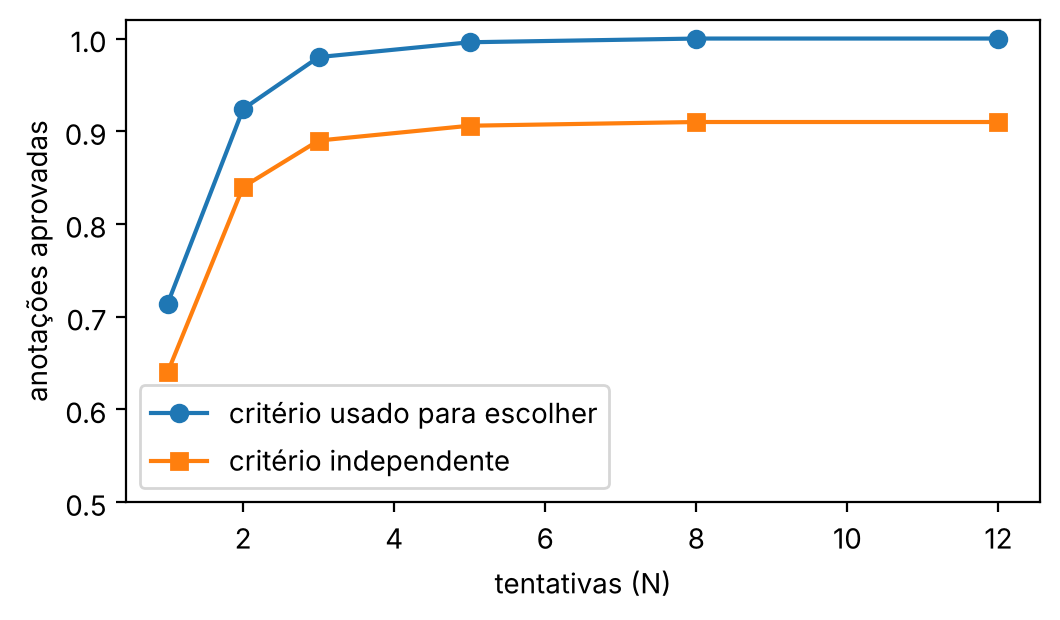

In [17]:
from aiind.evaluation import strict_note
from aiind.structured import coherent_note
def melhor_de(n, rng):
    primeira = None
    for _ in range(n):
        t = " ".join(generate(tri, rng)[0]); primeira = primeira or t
        if coherent_note(t):
            return t
    return primeira
Ns = [1, 2, 3, 5, 8, 12]
visto, independente = [], []
for N in Ns:
    rng = random.Random(0); amostra = [melhor_de(N, rng) for _ in range(500)]
    visto.append(sum(map(coherent_note, amostra)) / 500); independente.append(sum(map(strict_note, amostra)) / 500)
fig, ax = plt.subplots(figsize=(5.4, 3.2))
ax.plot(Ns, visto, "o-", label="critério usado para escolher"); ax.plot(Ns, independente, "s-", label="critério independente")
ax.set_xlabel("tentativas (N)"); ax.set_ylabel("anotações aprovadas"); ax.set_ylim(0.5, 1.02); ax.legend(); plt.tight_layout()
print("N:", Ns); print("pelo critério usado:     ", [f"{v:.0%}" for v in visto]); print("pelo critério independente:", [f"{v:.0%}" for v in independente])
exemplos = [t for t in amostra if coherent_note(t) and not strict_note(t)][:4]
print("\naprovadas pelo verificador, reprovadas pelo critério independente:"); [print("  ", e) for e in exemplos]

A curva do critério usado chega a 100 %; a do critério independente **estaciona abaixo**. A diferença são as anotações que o verificador não sabe reconhecer como erradas, como `prensa parada falta de tampa recalibrado` (mistura falta de material com ação de manutenção).

Esta é a lei de **Goodhart** aplicada à IA: quando uma medida vira meta, deixa de ser boa medida. Regras práticas:

- **Quem escolhe não avalia.** O critério de seleção e o de avaliação final têm que ser diferentes.
- Mantenha um **conjunto de teste separado** que nenhum ajuste (prompt, filtro, verificador) olhou.
- Desconfie de 100 %: significa que a métrica ficou fácil demais, não que o sistema é perfeito.

## 8. Avaliação comparativa: quem vence quem

Muitas vezes a pergunta não é "este sistema é bom?", e sim "qual de dois é melhor?". Pedir a pessoas ou a um juiz que escolham entre **duas respostas** costuma ser mais fácil e mais confiável do que dar notas absolutas. A partir de muitas comparações, um **ranking Elo** (o mesmo dos jogos de xadrez) dá a cada sistema uma pontuação: ganhar de um forte rende muitos pontos, de um fraco rende poucos.

Primeiro a mecânica, com jogadores cuja força verdadeira conhecemos (1300, 1150, 1000 e 750 antes de centralizar), para ver **quantas comparações** são necessárias:

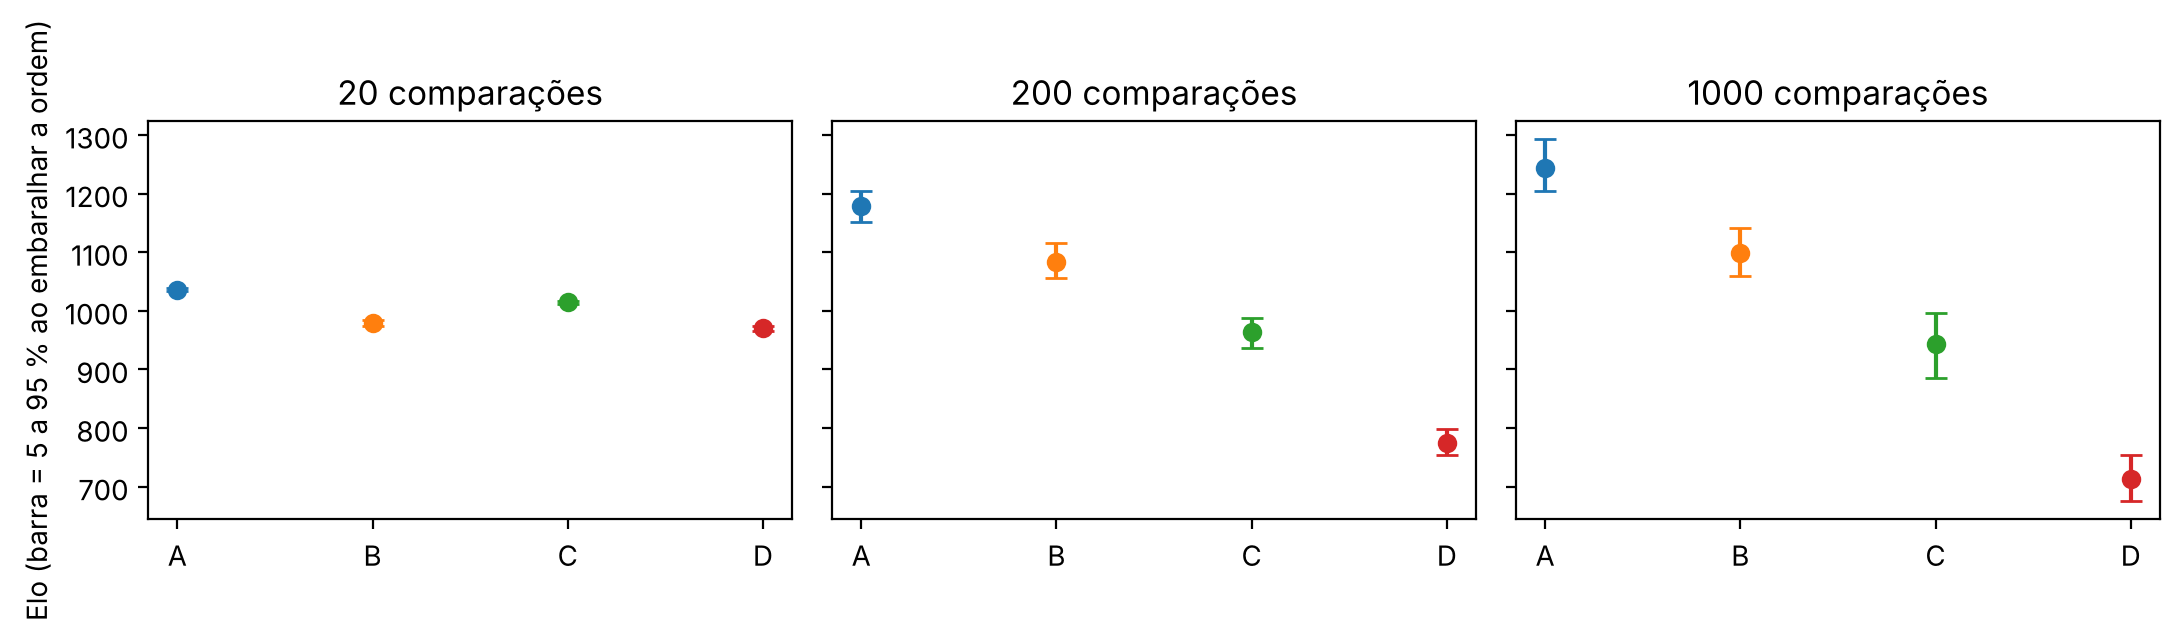

In [18]:
from aiind.evaluation import elo, elo_spread
verdadeira = {"A": 1300, "B": 1150, "C": 1000, "D": 750}
def disputas(n, seed):
    r = random.Random(seed); nomes = list(verdadeira); out = []
    for _ in range(n):
        a, b = r.sample(nomes, 2); pa = 1 / (1 + 10 ** ((verdadeira[b] - verdadeira[a]) / 400))
        out.append((a, b, 1.0 if r.random() < pa else 0.0))
    return out
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), sharey=True)
for ax, n in zip(axes, [20, 200, 1000]):
    sp = elo_spread(disputas(n, 1), rounds=100)
    for i, nome in enumerate(sorted(sp)):
        m, lo, hi = sp[nome]; ax.errorbar(i, m, yerr=[[m - lo], [hi - m]], fmt="o", capsize=4)
    ax.set_xticks(range(4), sorted(sp)); ax.set_title(f"{n} comparações")
axes[0].set_ylabel("Elo (barra = 5 a 95 % ao embaralhar a ordem)"); plt.tight_layout()

Com 20 comparações o ranking está **errado** (C à frente de B, A e C quase empatados), e as barras minúsculas enganam: elas só medem o efeito da **ordem** das disputas, não o erro de ter poucos jogos. Com 200 e 1000 comparações a ordem verdadeira aparece. Duas lições: o Elo precisa de **muitas comparações**, e por depender da ordem vale **embaralhar várias vezes** e reportar o intervalo, não um número só.

Agora, na prática, com os nossos sistemas gerando anotações para a mesma máquina: o bigrama, o trigrama, o trigrama com verificador (melhor de 3) e anotações escritas por pessoas (do corpus). O "juiz" aqui é o critério independente `strict_note` (empate quando os dois passam ou os dois falham), e 10 % dos votos são invertidos para simular um juiz imperfeito.

humano                   Elo   1091   (1059 a 1114)
trigrama + verificador   Elo   1064   (1033 a 1092)
trigrama                 Elo    982   (945 a 1015)
bigrama                  Elo    863   (827 a 900)


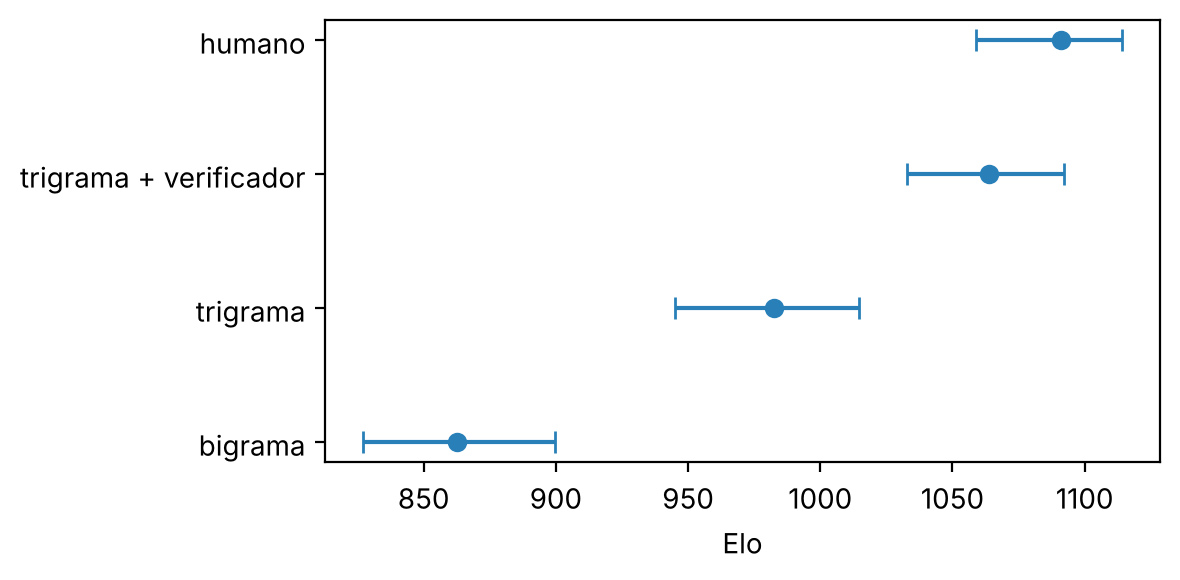

In [19]:
from aiind.corpus import MACHINES
bi = NGram(order=2).fit(tr_seqs)
humanas = notes(3000, seed=3)
def anotacao(sistema, m, r):
    if sistema == "humano":
        return r.choice([t for t in humanas if t.startswith(m)])
    modelo = bi if sistema == "bigrama" else tri
    if sistema != "trigrama + verificador":
        return " ".join(generate(modelo, r, prompt=[m])[0])
    primeira = None
    for _ in range(3):
        t = " ".join(generate(tri, r, prompt=[m])[0]); primeira = primeira or t
        if coherent_note(t):
            return t
    return primeira
sistemas = ["humano", "trigrama + verificador", "trigrama", "bigrama"]
r = random.Random(4); disputas_ia = []
for _ in range(800):
    a, b = r.sample(sistemas, 2); m = r.choice(MACHINES)
    sa, sb = strict_note(anotacao(a, m, r)), strict_note(anotacao(b, m, r))
    if r.random() < 0.1:
        sa, sb = sb, sa
    disputas_ia.append((a, b, 1.0 if sa and not sb else 0.0 if sb and not sa else 0.5))
sp = elo_spread(disputas_ia, rounds=100)
ordem = sorted(sp, key=lambda k: -sp[k][0])
fig, ax = plt.subplots(figsize=(6, 3))
for i, nome in enumerate(ordem):
    m, lo, hi = sp[nome]; ax.errorbar(m, i, xerr=[[m - lo], [hi - m]], fmt="o", capsize=4, color="#2980b9")
    print(f"{nome:24s} Elo {m:6.0f}   ({lo:.0f} a {hi:.0f})")
ax.set_yticks(range(len(ordem)), ordem); ax.invert_yaxis(); ax.set_xlabel("Elo"); plt.tight_layout()

O ranking separa o bigrama e o trigrama dos demais, mas as barras do **humano** e do **trigrama com verificador** se sobrepõem: com este juiz e este número de comparações, **não dá para dizer qual é melhor**. Isso não é um defeito do Elo, é honestidade: a diferença real entre os dois (cerca de 12 pontos percentuais no critério independente, com 3 tentativas) é pequena perto do ruído do juiz. Para separar, é preciso mais comparações ou um critério que enxergue o que os distingue.

Comparar é ótimo para dizer **quem é melhor**, mas não diz **se é bom o bastante**. Um sistema pode ganhar de todos e ainda errar demais para ir à linha de produção. Por isso a comparação se combina com a avaliação exata contra um gabarito.

## Erros comuns

- **Comparar perplexidade entre tokenizadores.** Use bits por caractere.
- **Medir perplexidade em texto que o modelo viu no treino.** Sempre em dados novos.
- **Avaliar com a mesma função usada para escolher.** Quem escolhe não avalia (Goodhart).
- **Média sem fatias.** Uma média alta esconde a fatia ruim.
- **Confiar no juiz sem medi-lo.** Meça contra pessoas, troque a ordem, controle o tamanho.
- **Tratar similaridade de embeddings como prova de que dizem a mesma coisa.** Negação passa batida.
- **Um número só no Elo.** Reporte o intervalo ao embaralhar a ordem.

## Confira o que ficou

**1. O que a perplexidade de 4 significa, em palavras?**

<details><summary>Ver resposta</summary>

Em média, o modelo hesita entre 4 opções igualmente prováveis a cada passo. Quanto menor, menos surpreso ele fica com o texto.

</details>

**2. Por que a perplexidade no treino cai com a ordem do modelo, mas em texto novo sobe a partir da ordem 4?**

<details><summary>Ver resposta</summary>

Sobreajuste: o modelo decora o treino. Perplexidade só vale em dados que ele não viu.

</details>

**3. Por que não se compara a perplexidade por token de um modelo de palavras com a de um de caracteres?**

<details><summary>Ver resposta</summary>

Cada token carrega uma quantidade diferente de texto. O comparável é bits por caractere do texto original.

</details>

**4. O registro exato é a melhor métrica para o extrator das anotações?**

<details><summary>Ver resposta</summary>

Depende do uso. Para a perda por categoria do OEE, a categoria certa é a medida funcional; para um Pareto de peças, o campo peça.

</details>

**5. Por que 'vedação sem vazamento' ficou perto de 'vedação vazando' nos embeddings?**

<details><summary>Ver resposta</summary>

Embeddings medem do que o texto trata, não o que ele afirma. Negação e números escapam.

</details>

**6. Como reduzir o viés de posição de um juiz?**

<details><summary>Ver resposta</summary>

Perguntar nas duas ordens e exigir concordância; se divergirem, o resultado é empate.

</details>

**7. Por que 100 % no critério usado para escolher não prova que o sistema é bom?**

<details><summary>Ver resposta</summary>

Quem escolhe está se avaliando. Um critério independente e um conjunto de teste separado mostram o que o verificador não vê (Goodhart).

</details>

## Exercícios

1. **Ordem 3 contra 4:** treine com 500 anotações em vez de 2000. O ponto em que a perplexidade de texto novo começa a subir muda? Por quê?
2. **Alarme:** calcule os bits por caractere de cada anotação nova e escolha um limite para soar o alarme com no máximo 5 % de falsos alarmes nas anotações normais. Quantas anotações embaralhadas ele pega?
3. **Métrica funcional:** crie a métrica "a parada conta como perda do OEE?" (falha, falta e retorno contam; planejada, não) e meça os três sistemas da seção 4.
4. **Embeddings:** aumente `dim` de 12 para 2 e para 40. A AUC muda? Por que 2 dimensões ainda funcionam?
5. **Negação:** acrescente ao corpus de embeddings anotações do tipo `vedação sem vazamento` e veja se a similaridade com `vedação vazando` cai.
6. **Juiz:** diminua `length_bias` para 0 e `position_bias` para 0. O que acontece com as medidas 2 e 3? E se aumentar o ruído?
7. **Goodhart:** escreva um terceiro critério (por exemplo, a anotação tem de ter no máximo 9 palavras) e veja o que ele diz sobre as saídas do melhor de N.

## Glossário

- **Entropia:** incerteza média de uma distribuição, em bits.
- **Entropia cruzada:** bits gastos por um modelo para codificar texto real. Mede o quanto o modelo se surpreende.
- **Perplexidade:** 2 elevado à entropia cruzada; as opções efetivas por passo.
- **Bits por caractere:** entropia cruzada por caractere do texto original; comparável entre tokenizadores.
- **Sobreajuste:** o modelo decora o treino e piora em texto novo.
- **Correção funcional:** avaliar executando ou usando a saída, e não comparando texto.
- **Embedding:** vetor que representa um texto; textos de sentido parecido ficam perto.
- **AUC:** chance de uma amostra positiva receber nota maior que uma negativa.
- **IA como juiz:** usar um modelo para dar nota ou comparar saídas de outros.
- **Rubrica:** critério escrito que o juiz segue.
- **Viés de posição / de verbosidade:** o juiz favorece a primeira opção / a resposta mais longa.
- **Kappa de Cohen:** concordância entre dois avaliadores descontando o acaso.
- **Elo:** pontuação a partir de comparações em pares.
- **Lei de Goodhart:** uma medida usada como meta deixa de ser boa medida.

## Próximo passo

**Notebook 04, capítulo 4 (Evaluate AI Systems):** montar um conjunto de avaliação de verdade para um sistema que responde perguntas sobre OEE, escolher critérios, medir o sistema inteiro e decidir entre modelos.